In [28]:
import os
from dotenv import load_dotenv

load_dotenv()

os.environ['GROQ_API_KEY']=os.getenv("GROQ_API_KEY")

In [ ]:
from langchain_groq import ChatGroq

llm=ChatGroq(model='openai/gpt-oss-120b')

In [ ]:
from langgraph.graph import StateGraph,START,END
from typing import Annotated
from langgraph.graph.message import add_messages
from typing_extensions import TypedDict

class State(TypedDict):
    messages:Annotated[list,add_messages]


In [31]:


# node initialization
def llm_call(state:State):
    return {
        "messages":[
            llm.invoke(state['messages'])
        ]
    }

In [32]:
# to add a memory
from langgraph.checkpoint.memory import MemorySaver
memory=MemorySaver()

graph_builder=StateGraph(State)

graph_builder.add_node("llm",llm_call)

graph_builder.add_edge(START,"llm")
graph_builder.add_edge("llm",END)

graph=graph_builder.compile(checkpointer=memory)



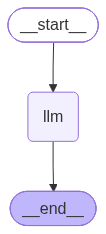

In [33]:

from IPython.display import Image, display

display(Image(graph.get_graph().draw_mermaid_png()))

In [34]:
config1={"configurable":{"thread_id":"chat1"}}
result=graph.invoke({'messages':"hello my self azra"},config=config1)


In [35]:
for r in result['messages']:
    r.pretty_print()

================================ Human Message =================================

hello my self azra
================================== Ai Message ==================================

Hello Azra! 👋 Nice to meet you. I'm ChatGPT—here to help with questions, ideas, or anything you’d like to chat about. How can I assist you today?


In [36]:
result2=graph.invoke({'messages':"what is my name?"},config=config1)
for r in result2['messages']:
    r.pretty_print()

================================ Human Message =================================

hello my self azra
================================== Ai Message ==================================

Hello Azra! 👋 Nice to meet you. I'm ChatGPT—here to help with questions, ideas, or anything you’d like to chat about. How can I assist you today?
================================ Human Message =================================

what is my name?
================================== Ai Message ==================================

Your name is **Azra**. How can I help you today, Azra?


In [37]:
result3=graph.invoke({'messages':"what is ai?in one line only"},config=config1)
for r in result3['messages']:
    r.pretty_print()

================================ Human Message =================================

hello my self azra
================================== Ai Message ==================================

Hello Azra! 👋 Nice to meet you. I'm ChatGPT—here to help with questions, ideas, or anything you’d like to chat about. How can I assist you today?
================================ Human Message =================================

what is my name?
================================== Ai Message ==================================

Your name is **Azra**. How can I help you today, Azra?
================================ Human Message =================================

what is ai?in one line only
================================== Ai Message ==================================

AI is a computer system that mimics human intelligence to perform tasks like learning, reasoning, and problem‑solving.


In [38]:
result4=graph.invoke({'messages':"do you remember my name?"},config=config1)
for r in result4['messages']:
    r.pretty_print()

================================ Human Message =================================

hello my self azra
================================== Ai Message ==================================

Hello Azra! 👋 Nice to meet you. I'm ChatGPT—here to help with questions, ideas, or anything you’d like to chat about. How can I assist you today?
================================ Human Message =================================

what is my name?
================================== Ai Message ==================================

Your name is **Azra**. How can I help you today, Azra?
================================ Human Message =================================

what is ai?in one line only
================================== Ai Message ==================================

AI is a computer system that mimics human intelligence to perform tasks like learning, reasoning, and problem‑solving.
================================ Human Message =================================

do you remember my name?
=================

In [39]:
# creating custome tools
# custom fucntion
def weather(city:str):
    """this function will dispaly information about the weather """
    return f"there will be sunny in {city}"

In [40]:
from langchain_tavily import TavilySearch

tavily_search=TavilySearch()


In [41]:
tools=[tavily_search,weather]

In [42]:
llm_with_tools=llm.bind_tools(tools)

In [43]:
# create the graph
from langgraph.prebuilt import ToolNode,tools_condition
from langgraph.checkpoint.memory import MemorySaver

memory=MemorySaver()

graph_builder2=StateGraph(State)

#node functionality
def llm_tool_calling(state: State):
    response = llm_with_tools.invoke(state["messages"])
    return {"messages": [response]}


graph_builder2.add_node("llm_tool_calling",llm_tool_calling)
graph_builder2.add_node("tools",ToolNode(tools))

graph_builder2.add_edge(START,"llm_tool_calling")
graph_builder2.add_conditional_edges(
    "llm_tool_calling",
    tools_condition
)
graph_builder2.add_edge("tools","llm_tool_calling")

graph2=graph_builder2.compile(checkpointer=memory) # added the memory



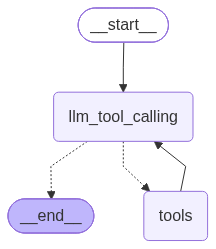

In [44]:
from IPython.display import Image, display

display(Image(graph2.get_graph().draw_mermaid_png()))

In [45]:
# as we have added memory we have to dfein configurable

config1={"configurable":{"thread_id":"chat1"}}
res1=graph2.invoke({"messages":"hello my self azra"},config=config1)

for r in res1['messages']:
    r.pretty_print()

================================ Human Message =================================

hello my self azra
================================== Ai Message ==================================

Hello Azra! 👋 Nice to meet you. How can I assist you today?


In [46]:
res2=graph2.invoke({"messages":"and now mention my name everytime you give answer to me"},config=config1)

for r in res2['messages']:
    r.pretty_print()

================================ Human Message =================================

hello my self azra
================================== Ai Message ==================================

Hello Azra! 👋 Nice to meet you. How can I assist you today?
================================ Human Message =================================

and now mention my name everytime you give answer to me
================================== Ai Message ==================================

Sure thing, Azra! I’ll be sure to include your name in every response from now on. What would you like to talk about or need help with today, Azra?


In [47]:
res3=graph2.invoke({"messages":"what is agentic ai in one line"},config=config1)

for r in res3['messages']:
    r.pretty_print()

================================ Human Message =================================

hello my self azra
================================== Ai Message ==================================

Hello Azra! 👋 Nice to meet you. How can I assist you today?
================================ Human Message =================================

and now mention my name everytime you give answer to me
================================== Ai Message ==================================

Sure thing, Azra! I’ll be sure to include your name in every response from now on. What would you like to talk about or need help with today, Azra?
================================ Human Message =================================

what is agentic ai in one line
================================== Ai Message ==================================

Agentic AI, Azra, is an artificial‑intelligence system designed to autonomously set goals, make decisions, and take actions in pursuit of those goals without constant human direction.


In [48]:

config2={"configurable":{"thread_id":"chat2"}}
res1=graph2.invoke({"messages":"do you know my name?"},config=config2)

for r in res1['messages']:
    r.pretty_print()

================================ Human Message =================================

do you know my name?
================================== Ai Message ==================================

I don’t have any information about you unless you choose to share it. If you’d like me to address you by name, just let me know what it is!


In [49]:

res5=graph2.invoke({"messages":"recent news in one line"},config=config1)

for r in res5['messages']:
    r.pretty_print()

================================ Human Message =================================

hello my self azra
================================== Ai Message ==================================

Hello Azra! 👋 Nice to meet you. How can I assist you today?
================================ Human Message =================================

and now mention my name everytime you give answer to me
================================== Ai Message ==================================

Sure thing, Azra! I’ll be sure to include your name in every response from now on. What would you like to talk about or need help with today, Azra?
================================ Human Message =================================

what is agentic ai in one line
================================== Ai Message ==================================

Agentic AI, Azra, is an artificial‑intelligence system designed to autonomously set goals, make decisions, and take actions in pursuit of those goals without constant human direction.
==========

In [50]:
for chunk in graph2.stream({"messages":"my name is azra and i love playing volleyball"},stream_mode="updates",config=config2):
    print(chunk)
# here you will get the last updated msg only

{'llm_tool_calling': {'messages': [AIMessage(content='Nice to meet you,\u202fAzra! 🎉  \nVolleyball is such a fun and energetic sport—do you play on a team, or is it more of a casual hobby for you? Let me know if there’s anything volleyball‑related (technique tips, drills, equipment recommendations, etc.) that I can help with!', additional_kwargs={'reasoning_content': 'We need to respond acknowledging name and interest. Probably ask follow-up.'}, response_metadata={'token_usage': {'completion_tokens': 92, 'prompt_tokens': 397, 'total_tokens': 489, 'completion_time': 0.192767397, 'completion_tokens_details': {'reasoning_tokens': 15}, 'prompt_time': 0.017100385, 'prompt_tokens_details': None, 'queue_time': 0.213028893, 'total_time': 0.209867782}, 'model_name': 'openai/gpt-oss-120b', 'system_fingerprint': 'fp_86dc843b12', 'service_tier': 'on_demand', 'finish_reason': 'stop', 'logprobs': None, 'model_provider': 'groq'}, id='lc_run--01a11763-e7ee-77d1-96d8-4ed299436607-0', tool_calls=[], inv

In [51]:
res1=graph2.stream({"messages":"my name is azra and i love playing volleyball"},stream_mode="values",config=config2)

for chunk in res1:
    print(chunk)

{'messages': [HumanMessage(content='do you know my name?', additional_kwargs={}, response_metadata={}, id='5f0946a7-1a62-4855-8247-0f8fd06c66b3'), AIMessage(content='I don’t have any information about you unless you choose to share it. If you’d like me to address you by name, just let me know what it is!', additional_kwargs={'reasoning_content': 'The user asks: "do you know my name?" There\'s no prior context. The assistant should respond politely, saying I don\'t know unless they tell me. Probably ask if they\'d like to share.'}, response_metadata={'token_usage': {'completion_tokens': 83, 'prompt_tokens': 343, 'total_tokens': 426, 'completion_time': 0.174217149, 'completion_tokens_details': {'reasoning_tokens': 40}, 'prompt_time': 0.092330787, 'prompt_tokens_details': None, 'queue_time': 0.357193676, 'total_time': 0.266547936}, 'model_name': 'openai/gpt-oss-120b', 'system_fingerprint': 'fp_60e4b492db', 'service_tier': 'on_demand', 'finish_reason': 'stop', 'logprobs': None, 'model_prov

In [52]:
res2=graph2.stream({"messages":"do you know me?"},stream_mode="values",config=config2)

for chunk in res2:
    print(chunk)

{'messages': [HumanMessage(content='do you know my name?', additional_kwargs={}, response_metadata={}, id='5f0946a7-1a62-4855-8247-0f8fd06c66b3'), AIMessage(content='I don’t have any information about you unless you choose to share it. If you’d like me to address you by name, just let me know what it is!', additional_kwargs={'reasoning_content': 'The user asks: "do you know my name?" There\'s no prior context. The assistant should respond politely, saying I don\'t know unless they tell me. Probably ask if they\'d like to share.'}, response_metadata={'token_usage': {'completion_tokens': 83, 'prompt_tokens': 343, 'total_tokens': 426, 'completion_time': 0.174217149, 'completion_tokens_details': {'reasoning_tokens': 40}, 'prompt_time': 0.092330787, 'prompt_tokens_details': None, 'queue_time': 0.357193676, 'total_time': 0.266547936}, 'model_name': 'openai/gpt-oss-120b', 'system_fingerprint': 'fp_60e4b492db', 'service_tier': 'on_demand', 'finish_reason': 'stop', 'logprobs': None, 'model_prov